# NSL-KDD: Perbandingan Langsung Model Biner

**Arah riset:** membandingkan metode stacking dengan baseline SVM, Logistic Regression, dan KNN dari paper Vibhute et al. (2024), menggunakan dataset, baris fit/evaluasi, target biner, preprocessing, serta metrik yang sama di dalam eksperimen ini.

**Primary metric: accuracy.** Precision/recall/F1 attack, Macro-F1, MCC, ROC-AUC, PR-AUC, false-positive rate, confusion matrix, dan biaya komputasi tetap dilaporkan. Accuracy 98,24% dari paper adalah referensi historis; kemenangan empiris diuji terhadap **baseline yang dijalankan ulang pada kasus yang sama**, bukan dengan mengurangkan dua angka dari eksperimen berbeda.

Belum ada klaim stacking menang. Profil `journal` memakai lima seed dan data lengkap. Profil `smoke` hanya tes program pada data terbatas; hasilnya tidak boleh digunakan sebagai hasil penelitian.

## 1. Rekonstruksi paper dan batas kesetaraan

Paper: *Towards Detection of Network Anomalies using Machine Learning Algorithms on the NSL-KDD Benchmark Datasets*, Procedia Computer Science 233 (2024), 960–969, DOI 10.1016/j.procs.2024.03.285.

Paper menyebut **75/25** pada bagian dataset/hasil dan **70/30** pada seleksi fitur. Angka 125.973 dan 22.544 adalah ukuran file NSL-KDD resmi, bukan pembagian 75/25. Confusion matrix KNN (Figure 3) berjumlah **37.792**, terdiri dari **20.083 normal dan 17.709 attack**. Split standar `test_size=.30, random_state=42, shuffle=True, stratify=None` pada file frozen menghasilkan jumlah kasus dan kedua marginal kelas yang sama. Karena indeks split, source code, dan daftar sembilan fitur penulis tidak tersedia, kecocokan marginal ini belum membuktikan replikasi persis.

Protokol ditetapkan sebelum model dijalankan:

| Protokol | Fitting | Evaluasi | Peran |
|---|---|---|---|
| `paper70` | 70% KDDTrain+ | 30% KDDTrain+ (37.792 baris penuh) | Rekonstruksi utama, cocok jumlah kasus Figure 3 |
| `paper75` | 75% KDDTrain+ | 25% KDDTrain+ (31.494 baris penuh) | Sensitivitas untuk pernyataan 75/25 |
| `official` | Seluruh KDDTrain+ (125.973) | Seluruh KDDTest+ (22.544) | Uji generalisasi terpisah |

Semua model dan semua arm memakai **row IDs identik untuk setiap protokol dan seed**. Holdout menggunakan shuffle tanpa stratifikasi sesuai rekonstruksi marginal Figure 3; ini berbeda dari stratified split. File train dan test tidak dicampur. `difficulty` dibuang dari input; target `normal=0`, seluruh serangan `=1`. Tidak ada pemilihan model/k berdasarkan test. Angka official test tidak dibandingkan seolah-olah merupakan akurasi holdout paper.

NSL-KDD juga memiliki beberapa input identik berlabel berbeda ketika hanya 41 fitur dipakai. Baris resmi dipertahankan untuk menjaga populasi perbandingan. Overlap dilaporkan, dan metrik tanpa overlap menjadi diagnosis tambahan. Fold OOF stacking selalu memisahkan kelompok input identik.

## 2. Setup Colab
Jalankan semua sel pada runtime baru. Dataset NSL-KDD diunduh otomatis dari mirror publik yang dibekukan pada satu commit, dengan SHA-256 dan jumlah baris diverifikasi. Halaman resmi UNB kini menyatakan dataset tidak lagi tersedia untuk diunduh. Sumber mirror dibedakan dari sumber resmi dan sitasi NSL-KDD disimpan.

Gunakan Google Drive untuk `OUT_DIR` jika run lama berisiko terputus. `RESUME=True` melanjutkan suite yang belum selesai hanya bila konfigurasi/data/versi engine sama; checkpoint lengkap diperiksa checksum-nya. Jangan mengganti seed atau parameter ketika melanjutkan direktori lama.

In [ ]:
import os, sys, subprocess
from pathlib import Path
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
INSTALL_DEPENDENCIES = IN_COLAB
if INSTALL_DEPENDENCIES:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
        'numpy==2.3.5', 'pandas==3.0.1', 'scikit-learn==1.7.2',
        'xgboost==3.4.1', 'lightgbm==4.7.0', 'catboost==1.2.10',
        'scipy==1.18.1', 'matplotlib==3.11.2'])
print(sys.version)

3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [ ]:
import os
import sys
import json
import time
import hashlib
import platform
import warnings
import urllib.request
from pathlib import Path
from dataclasses import dataclass, asdict
import importlib.metadata as package_metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef, roc_auc_score, average_precision_score,
    confusion_matrix)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

ENGINE_VERSION = 'nslkdd-direct-v2'
FEATURES = '''duration protocol_type service flag src_bytes dst_bytes land wrong_fragment urgent
hot num_failed_logins logged_in num_compromised root_shell su_attempted num_root
num_file_creations num_shells num_access_files num_outbound_cmds is_host_login is_guest_login
count srv_count serror_rate srv_serror_rate rerror_rate srv_rerror_rate same_srv_rate
diff_srv_rate srv_diff_host_rate dst_host_count dst_host_srv_count dst_host_same_srv_rate
dst_host_diff_srv_rate dst_host_same_src_port_rate dst_host_srv_diff_host_rate
dst_host_serror_rate dst_host_srv_serror_rate dst_host_rerror_rate dst_host_srv_rerror_rate'''.split()
CATS = ['protocol_type', 'service', 'flag']
NUMS = [f for f in FEATURES if f not in CATS]
TREE_NAMES = ['RF', 'XGB', 'LGBM', 'CAT']
METHODS = ['PAPER_SVM', 'PAPER_LR', 'PAPER_KNN', *TREE_NAMES, 'VOTE', 'STACK']
DATA_COMMIT = '27bbbdf5c5cccf9970b8b6037a0f19dc09c5a0a9'
DATA_BASE = f'https://raw.githubusercontent.com/Jehuty4949/NSL_KDD/{DATA_COMMIT}/'
DATA_SPECS = {
    'KDDTrain+.txt': (125973, '1b86d2f957b33082081bba410fe129b475efebcc13c9014c3f447c8271aadf95'),
    'KDDTest+.txt': (22544, 'fa46b0935342616aa83b7c2578db355b6a7aaabbc492248172c7a1e8b7ab8f84'),
}
PAPER_ACCURACY = {'PAPER_SVM': .8758, 'PAPER_LR': .8886, 'PAPER_KNN': .9824}
PROTOCOLS = ['paper70', 'paper75', 'official']
ARMS = ['rf_threshold_encoded', 'rf_top9_group', 'all']

@dataclass
class DirectConfig:
    profile: str = 'journal'
    seeds: tuple = (42, 52, 62, 72, 82)
    protocols: tuple = tuple(PROTOCOLS)
    arms: tuple = tuple(ARMS)
    folds: int = 5
    trees: int = 160
    selector_trees: int = 300
    selector_seed: int = 100
    rf_threshold: float = .05
    raw_top_k: int = 9
    svm_c: float = 10.0
    lr_max_iter: int = 100
    knn_k: int = 5
    jobs: int = 2
    prediction_batch: int = 4096
    smoke_train_per_class: int = 0
    smoke_test_per_class: int = 0
    bootstrap_repetitions: int = 1000
    resume: bool = False

PLANNED_DIRECT = dict(seeds=(42, 52, 62, 72, 82), protocols=tuple(PROTOCOLS), arms=tuple(ARMS),
    folds=5, trees=160, selector_trees=300, selector_seed=100, rf_threshold=.05, raw_top_k=9,
    svm_c=10., lr_max_iter=100, knn_k=5, smoke_train_per_class=0, smoke_test_per_class=0,
    bootstrap_repetitions=1000)

def direct_config(profile='journal'):
    if profile == 'journal':
        return DirectConfig()
    if profile == 'smoke':
        return DirectConfig(profile='smoke', seeds=(42, 52), folds=2, trees=10,
            selector_trees=20, smoke_train_per_class=250, smoke_test_per_class=80,
            bootstrap_repetitions=100)
    raise ValueError('Choose journal or smoke')

def status_label(cfg):
    if not cfg.seeds or len(set(cfg.seeds)) != len(cfg.seeds):
        raise ValueError('Seeds must be distinct and nonempty')
    if not set(cfg.protocols) <= set(PROTOCOLS) or not set(cfg.arms) <= set(ARMS):
        raise ValueError('Unknown comparison protocol or feature-selection arm')
    if 'paper70' not in cfg.protocols or 42 not in cfg.seeds:
        raise ValueError('Retain paper70 and reference seed 42 for the primary comparison')
    if not set(ARMS) <= set(cfg.arms) or cfg.raw_top_k != 9:
        raise ValueError('Keep all three prespecified arms and top-9 for the direct-comparison protocol')
    complete = cfg.profile == 'journal' and all(
        (tuple(getattr(cfg, k)) if k in ['seeds', 'protocols', 'arms'] else getattr(cfg, k)) == v
        for k, v in PLANNED_DIRECT.items())
    label = 'SMOKE' if cfg.profile == 'smoke' else ('JOURNAL' if complete else 'JOURNAL CUSTOM')
    return dict(label=f'{label} | {len(cfg.seeds)} seeds', planned_protocol_complete=complete,
                exact_author_replication=False, engine=ENGINE_VERSION)

def write_json(path, obj):
    Path(path).write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str), encoding='utf-8')

def file_sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()

def algorithm_signature():
    """Detect edited model/selection/split code before reusing cached suites."""
    import ast
    import inspect
    import textwrap
    functions = [DirectInputs.fit_transform, DirectInputs.transform, estimator,
                 positive_probability, fit_suite, make_protocol, oof_splits, binary_metrics]
    canonical = [ast.dump(ast.parse(textwrap.dedent(inspect.getsource(fn))),
                          include_attributes=False) for fn in functions]
    return hashlib.sha256('\n'.join(canonical).encode()).hexdigest()

In [ ]:
PROFILE = os.environ.get('NSL_PROFILE', 'journal')
CFG = direct_config(PROFILE)
DATA_DIR = Path(os.environ.get('NSL_DATA_DIR', '/content/nsl_kdd'))
OUT_DIR = Path(os.environ.get('NSL_OUT_DIR', '/content/nslkdd_direct_results'))
AUTO_DOWNLOAD = True
RESUME = os.environ.get('NSL_RESUME', '0') == '1'  # True: OUT_DIR menunjuk run lama yang identik.
CFG.resume = RESUME
# Jika memakai Drive, mount terlebih dahulu lalu ubah DATA_DIR/OUT_DIR:
# from google.colab import drive
# drive.mount('/content/drive')
print(json.dumps(asdict(CFG), indent=2))
print(status_label(CFG))

{
  "profile": "journal",
  "seeds": [
    42,
    52,
    62,
    72,
    82
  ],
  "protocols": [
    "paper70",
    "paper75",
    "official"
  ],
  "arms": [
    "rf_threshold_encoded",
    "rf_top9_group",
    "all"
  ],
  "folds": 5,
  "trees": 160,
  "selector_trees": 300,
  "selector_seed": 100,
  "rf_threshold": 0.05,
  "raw_top_k": 9,
  "svm_c": 10.0,
  "lr_max_iter": 100,
  "knn_k": 5,
  "jobs": 2,
  "prediction_batch": 4096,
  "smoke_train_per_class": 0,
  "smoke_test_per_class": 0,
  "bootstrap_repetitions": 1000,
  "resume": false
}
{'label': 'JOURNAL | 5 seeds', 'planned_protocol_complete': True, 'exact_author_replication': False, 'engine': 'nslkdd-direct-v2'}


## 3. Data, provenance, dan parameter baseline

Sumber input adalah `KDDTrain+.txt` dan `KDDTest+.txt` **NSL-KDD**, masing-masing 43 kolom: 41 fitur + attack name + difficulty. File KDD Cup 99 sebelumnya tidak dipakai dan tidak dapat menggantikan file ini.

- SVM: `SVC(kernel='linear', C=10)`, reference seed 42.
- Logistic Regression: bobot kelas uniform, `max_iter=100`, ambang 0,5. Solver LBFGS, C=1 dan tolerance default adalah asumsi rekonstruksi karena paper tidak merincinya. Peringatan konvergensi disimpan, bukan disembunyikan.
- KNN: k=5, Euclidean, bobot uniform. Pernyataan paper tentang “30 iterations” tidak diterjemahkan menjadi parameter yang tidak ada pada KNeighborsClassifier.
- Semua model memakai imputation/MinMax/OHE yang hanya di-fit pada bagian training yang sah. Tidak ada oversampling atau class weighting pada protokol utama ini.
- Paper juga menyebut 10-fold CV; detailnya tidak cukup untuk merekonstruksi indeks dan hasil CV tersebut. Lima fold di sini adalah konstruksi OOF stacking, bukan klaim mengulang CV paper.

In [ ]:
def download_nsl(data_dir):
    directory = Path(data_dir)
    directory.mkdir(parents=True, exist_ok=True)
    for name, (_, expected_hash) in DATA_SPECS.items():
        path = directory / name
        if not path.exists():
            partial = path.with_suffix(path.suffix + '.download')
            with urllib.request.urlopen(DATA_BASE + name, timeout=120) as response, open(partial, 'wb') as stream:
                while block := response.read(1024*1024):
                    stream.write(block)
            if file_sha(partial) != expected_hash:
                raise ValueError(f'Download checksum mismatch: {name}')
            partial.replace(path)
        if file_sha(path) != expected_hash:
            raise ValueError(f'{name}: bytes differ from frozen mirror; use a new data folder to download the pinned copy')
    (directory / 'SOURCE_AND_CITATION.txt').write_text(
        'NSL-KDD (2009), Canadian Institute for Cybersecurity, University of New Brunswick.\n'
        'M. Tavallaee, E. Bagheri, W. Lu, A. A. Ghorbani (2009), A Detailed Analysis of the KDD CUP 99 Data Set, CISDA.\n'
        'Official description and redistribution terms: https://www.unb.ca/cic/datasets/nsl.html\n'
        'The official page no longer distributes the data. These files are from an unofficial mirror, frozen at:\n'
        + DATA_BASE + '\nSHA-256 values are recorded in the experiment code and dataset audit.\n', encoding='utf-8')
    return directory

def paper_specification():
    return dict(doi='10.1016/j.procs.2024.03.285', dataset='NSL-KDD', target='normal=0; attack=1',
        historical_accuracy=PAPER_ACCURACY,
        split_reconstruction=dict(primary='paper70: shuffled, unstratified 70/30 on KDDTrain+; seed 42 reference',
            sensitivity='paper75: shuffled, unstratified 75/25 on KDDTrain+',
            external='official: KDDTrain+ -> KDDTest+',
            evidence='Figure 3 totals 37792 (20083 normal, 17709 attack); standard KDDTrain+ with test_size=.30, random_state=42, stratify=None matches both class margins',
            limitation='Paper also states 75/25 and calls 125973/22544 a 75/25 split; author indices and code not provided'),
        preprocessing='Training-only imputation, numeric min-max, categorical one-hot; difficulty excluded',
        feature_selection=dict(documented='RF 300 trees, random_state=100, threshold=.05, reports nine features',
            encoded_threshold='Literal post-encoding threshold interpretation; actual selected count is reported',
            group_top9='Controlled group-aware alternative; exactly nine raw features, all their dummies retained',
            limitation='Nine selected names and whether importances refer to raw or encoded features are not specified'),
        baseline_parameters=dict(SVM='SVC linear, C=10; seed varies; paper reference seed=42; gamma irrelevant for linear kernel',
            LR='Uniform class weights, max_iter=100, threshold=.5; C=1, lbfgs and tolerance are reconstruction assumptions',
            KNN='k=5, Euclidean, uniform weights; paper mentions 30 iterations, which is not a KNeighborsClassifier parameter',
            unspecified='Other classifier/selector settings use recorded sklearn defaults, including RF criterion=gini; these are reconstruction assumptions'),
        cross_validation='Paper mentions ten-fold CV without sufficient split/results detail; default five-fold OOF here constructs stacking, not a claimed reproduction of that CV',
        claims='Direct empirical comparison is against rerun baselines on identical saved cases; historical 98.24% is contextual, not a paired test or exact reproduction target')

def read_nsl(data_dir, out):
    frames, source = [], {}
    for name, (expected_rows, expected_hash) in DATA_SPECS.items():
        path = Path(data_dir) / name
        if file_sha(path) != expected_hash:
            raise ValueError(f'Unexpected source checksum: {name}')
        df = pd.read_csv(path, header=None)
        if df.shape != (expected_rows, 43):
            raise ValueError(f'{name}: expected NSL-KDD {expected_rows} x 43, got {df.shape}. KDD99 is not interchangeable.')
        df.columns = FEATURES + ['attack', 'difficulty']
        df[NUMS] = df[NUMS].apply(pd.to_numeric, errors='raise').astype('float64')
        df[NUMS] = df[NUMS].mask(df[NUMS] == 0, 0.0)
        if df[FEATURES].isna().any().any() or not np.isfinite(df[NUMS]).all().all():
            raise ValueError('Unexpected missing/non-finite values; inspect source rather than silently dropping rows')
        df['attack'] = df.attack.str.strip().str.rstrip('.').str.lower()
        if not df.attack.str.fullmatch('[a-z_0-9]+').all() or 'normal' not in set(df.attack):
            raise ValueError('Invalid label column')
        df['y'] = (df.attack != 'normal').astype(int)
        df['row_id'] = [f'{name}:{i}' for i in range(len(df))]
        frames.append(df)
        source[name] = dict(rows=len(df), sha256=expected_hash, url=DATA_BASE + name,
                           normal=int((df.y == 0).sum()), attack=int((df.y == 1).sum()))
    train, test = frames
    combined = pd.concat([train[FEATURES], test[FEATURES]], ignore_index=True)
    hashes = pd.util.hash_pandas_object(combined, index=False).to_numpy()
    distinct = ~combined.duplicated()
    if pd.Series(hashes[distinct]).duplicated().any():
        raise ValueError('Raw-input hash collision')
    train['group'] = hashes[:len(train)]
    test['group'] = hashes[len(train):]
    audit = dict(dataset='NSL-KDD', source=source, mirror_is_unofficial=True, mirror_commit=DATA_COMMIT,
        original_author_split_available=False, difficulty_used_as_feature=False,
        train_duplicate_input_rows=int(train.group.duplicated().sum()),
        train_binary_conflict_groups=int(train.groupby('group').y.nunique().gt(1).sum()),
        official_test_overlap_rows=int(test.group.isin(train.group).sum()),
        row_policy='Preserve official rows, including conflicts, for comparability; report overlaps separately')
    _, reference = make_protocol(train, test, 'paper70', 42)
    observed = {str(k):int(v) for k,v in reference.y.value_counts().sort_index().items()}
    audit['full_source_reference_case_margins'] = dict(protocol='paper70', seed=42,
        expected_figure3={'0':20083,'1':17709}, observed=observed,
        matches_paper_margins=(observed=={'0':20083,'1':17709}),
        exact_author_indices_proven=False)
    write_json(Path(out) / 'dataset_audit.json', audit)
    write_json(Path(out) / 'paper_reconstruction.json', paper_specification())
    return train, test, audit

def cap_classes(frame, cap):
    if not cap:
        return frame.reset_index(drop=True)
    return pd.concat([p.sample(min(len(p), cap), random_state=2026) for _, p in frame.groupby('y')]).reset_index(drop=True)

def make_protocol(train, test, protocol, seed):
    if protocol == 'official':
        return train.reset_index(drop=True), test.reset_index(drop=True)
    fraction = {'paper70': .30, 'paper75': .25}[protocol]
    a, b = train_test_split(np.arange(len(train)), test_size=fraction,
                           random_state=seed, shuffle=True, stratify=None)
    return train.iloc[a].reset_index(drop=True), train.iloc[b].reset_index(drop=True)

def oof_splits(frame, folds, seed):
    # Stratify representative labels of raw-input groups, then expand each group.
    # This avoids costly greedy assignment for ~126k mostly-singleton groups.
    groups = frame.groupby('group', sort=True).y.mean()
    representative_y = (groups.to_numpy() >= .5).astype(int)
    cv = StratifiedKFold(folds, shuffle=True, random_state=seed)
    covered = np.zeros(len(frame), dtype=int)
    result = []
    for a, b in cv.split(groups, representative_y):
        valid_groups = groups.index.to_numpy()[b]
        mask = frame.group.isin(valid_groups).to_numpy()
        fit, valid = np.flatnonzero(~mask), np.flatnonzero(mask)
        assert not set(frame.group.iloc[fit]) & set(frame.group.iloc[valid])
        assert set(frame.y.iloc[fit]) == {0, 1} and set(frame.y.iloc[valid]) == {0, 1}
        covered[valid] += 1
        result.append((fit, valid))
    assert (covered == 1).all()
    return result

In [ ]:
if AUTO_DOWNLOAD:
    download_nsl(DATA_DIR)
else:
    print('Pastikan dua file NSL-KDD frozen tersedia di', DATA_DIR)
print('Data:', DATA_DIR)
print(json.dumps(paper_specification(), indent=2))

Data: /content/nsl_kdd
{
  "doi": "10.1016/j.procs.2024.03.285",
  "dataset": "NSL-KDD",
  "target": "normal=0; attack=1",
  "historical_accuracy": {
    "PAPER_SVM": 0.8758,
    "PAPER_LR": 0.8886,
    "PAPER_KNN": 0.9824
  },
  "split_reconstruction": {
    "primary": "paper70: shuffled, unstratified 70/30 on KDDTrain+; seed 42 reference",
    "sensitivity": "paper75: shuffled, unstratified 75/25 on KDDTrain+",
    "external": "official: KDDTrain+ -> KDDTest+",
    "evidence": "Figure 3 totals 37792 (20083 normal, 17709 attack); standard KDDTrain+ with test_size=.30, random_state=42, stratify=None matches both class margins",
    "limitation": "Paper also states 75/25 and calls 125973/22544 a 75/25 split; author indices and code not provided"
  },
  "preprocessing": "Training-only imputation, numeric min-max, categorical one-hot; difficulty excluded",
  "feature_selection": {
    "documented": "RF 300 trees, random_state=100, threshold=.05, reports nine features",
    "encoded_thresh

## 4. Seleksi fitur dan kontrol kontribusi metode

Paper menyebut RF 300 trees, random_state 100, threshold 0,05 dan sembilan fitur, tetapi tidak memberi daftar fitur atau kejelasan raw/encoded. Karena itu, dua interpretasi dipisahkan dan tidak dipilih setelah melihat test:

| Arm | Definisi |
|---|---|
| `rf_threshold_encoded` | RF importance ≥0,05 setelah encoding; jumlah aktual dilaporkan, tidak dipaksa menjadi sembilan |
| `rf_top9_group` | Jumlahkan importance seluruh dummy dari fitur asli; ambil sembilan kelompok fitur asli; semua dummy kelompok dipertahankan |
| `all` | Semua 41 fitur asli setelah encoding, tanpa seleksi |

Ketiga baseline paper, RF, XGBoost, LightGBM, CatBoost, soft voting dan stacking semuanya dinilai pada ketiga arm. **Dalam satu arm, mereka memakai input transformasi dan seleksi refit yang sama.** OOF stacking menghitung ulang preprocessing/RF selection di setiap fold fit; pemilihan fitur global sebelum OOF tidak dipakai.

Kontras utama yang ditetapkan: **STACK versus rerun KNN pada `rf_top9_group`, protokol `paper70`**, dengan seed 42 sebagai reference run dan lima seed sebagai pemeriksaan kestabilan. Perbandingan dengan KNN pada `rf_threshold_encoded` menjadi kontras metode lengkap tambahan. Arm `all` menguji kontribusi feature selection. Tidak ada pencarian k agar angka mendekati atau melampaui 98,24%.

In [ ]:
class DirectInputs:
    def __init__(self, arm, cfg):
        self.arm, self.cfg = arm, cfg

    def fit_transform(self, X, y):
        if list(X.columns) != FEATURES:
            raise ValueError('Only the 41 input features may enter preprocessing')
        self.prep = ColumnTransformer([
            ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                              ('scale', MinMaxScaler())]), NUMS),
            ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.float32))]), CATS)
        ], sparse_threshold=0)
        matrix = np.asarray(self.prep.fit_transform(X), dtype=np.float32)
        self.names = self.prep.get_feature_names_out()
        raw_names = list(NUMS)
        for col, categories in zip(CATS, self.prep.named_transformers_['cat'].named_steps['onehot'].categories_):
            raw_names.extend([col] * len(categories))
        self.raw_names = np.asarray(raw_names)
        assert len(self.raw_names) == matrix.shape[1]
        self.importances = np.full(matrix.shape[1], np.nan)
        if self.arm == 'all':
            self.selected = np.ones(matrix.shape[1], dtype=bool)
        else:
            selector = RandomForestClassifier(n_estimators=self.cfg.selector_trees,
                random_state=self.cfg.selector_seed, n_jobs=self.cfg.jobs)
            selector.fit(matrix, y)
            self.importances = selector.feature_importances_
            if self.arm == 'rf_threshold_encoded':
                self.selected = self.importances >= self.cfg.rf_threshold
                if not self.selected.any():
                    raise ValueError('RF threshold selected no features; report this deviation instead of silently changing threshold')
            elif self.arm == 'rf_top9_group':
                scores = np.array([self.importances[self.raw_names == f].sum() for f in FEATURES])
                top = np.argsort(-scores, kind='stable')[:self.cfg.raw_top_k]
                self.selected = np.isin(self.raw_names, np.asarray(FEATURES)[top])
                assert len(set(self.raw_names[self.selected])) == self.cfg.raw_top_k
            else:
                raise ValueError(self.arm)
        return matrix[:, self.selected]

    def transform(self, X):
        return np.asarray(self.prep.transform(X), dtype=np.float32)[:, self.selected]

    def records(self, context):
        return [{**context, 'encoded_feature': str(name), 'raw_feature': str(raw),
                 'rf_importance': float(score), 'selected': bool(selected)}
            for name, raw, score, selected in zip(self.names, self.raw_names, self.importances, self.selected)]

def estimator(name, seed, cfg):
    if name == 'PAPER_SVM':
        return SVC(kernel='linear', C=cfg.svm_c, random_state=seed, cache_size=512)
    if name == 'PAPER_LR':
        return LogisticRegression(C=1., solver='lbfgs', max_iter=cfg.lr_max_iter,
                                  class_weight=None, random_state=seed)
    if name == 'PAPER_KNN':
        return KNeighborsClassifier(n_neighbors=cfg.knn_k, weights='uniform',
                                    metric='minkowski', p=2, n_jobs=cfg.jobs)
    if name == 'RF':
        return RandomForestClassifier(n_estimators=cfg.trees, min_samples_leaf=2,
                                       random_state=seed, n_jobs=cfg.jobs)
    if name == 'XGB':
        return XGBClassifier(n_estimators=cfg.trees, max_depth=5, learning_rate=.07,
            subsample=.85, colsample_bytree=.85, tree_method='hist', objective='binary:logistic',
            eval_metric='logloss', random_state=seed, n_jobs=cfg.jobs)
    if name == 'LGBM':
        return LGBMClassifier(n_estimators=cfg.trees, learning_rate=.07, num_leaves=31,
            verbosity=-1, random_state=seed, n_jobs=cfg.jobs, deterministic=True, force_col_wise=True)
    if name == 'CAT':
        return CatBoostClassifier(iterations=cfg.trees, depth=6, learning_rate=.07,
            loss_function='Logloss', random_seed=seed, thread_count=cfg.jobs,
            verbose=False, allow_writing_files=False)
    raise ValueError(name)

def positive_probability(model, X):
    column = np.flatnonzero(np.asarray(model.classes_) == 1)
    assert len(column) == 1
    p = np.asarray(model.predict_proba(X))[:, column[0]]
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    return p

## 5. Model, OOF stacking dan metrik biner
Meta-model Logistic Regression belajar dari probabilitas OOF empat tree learner. Voting menggunakan rata-rata probabilitas learner yang sama. SVM memakai decision score untuk AUC; skor itu tidak dianggap probabilitas terkalibrasi. Accuracy dihitung dari prediksi kelas, terpisah dari Macro-F1/MCC.

Waktu stacking mencakup konstruksi OOF dan meta fit; waktu model tunggal mencakup satu preprocessing/selection refit dan model fit. Waktu prediksi KNN/SVM dicatat pada batch yang sama. Peringatan, selected features, OOF, dan prediksi setiap model disimpan.

In [ ]:
def binary_metrics(y, pred, score):
    y, pred, score = np.asarray(y).ravel(), np.asarray(pred).ravel(), np.asarray(score).ravel()
    assert len(y) == len(pred) == len(score) and set(np.unique(y)) == {0, 1}
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(n=len(y), accuracy=accuracy_score(y, pred), accuracy_percent=100*accuracy_score(y, pred),
        precision_attack=precision_score(y, pred, zero_division=0),
        recall_attack=recall_score(y, pred, zero_division=0),
        f1_attack=f1_score(y, pred, zero_division=0),
        macro_f1=f1_score(y, pred, average='macro', labels=[0, 1], zero_division=0),
        balanced_accuracy=balanced_accuracy_score(y, pred), mcc=matthews_corrcoef(y, pred),
        roc_auc=roc_auc_score(y, score), pr_auc=average_precision_score(y, score),
        false_positive_rate=float(fp/(fp+tn)), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def fit_suite(train, evaluation, cfg, seed, protocol, arm, directory):
    context = dict(protocol=protocol, seed=seed, arm=arm)
    y = train.y.to_numpy()
    X, Xe = train[FEATURES], evaluation[FEATURES]
    oof = np.full((len(train), 4), np.nan, dtype=np.float32)
    records, warning_rows, fold_rows = [], [], []
    oof_seconds = 0.
    for fold, (a, b) in enumerate(oof_splits(train, cfg.folds, seed)):
        start = time.perf_counter()
        prep = DirectInputs(arm, cfg)
        xa, xb = prep.fit_transform(X.iloc[a], y[a]), None
        xb = prep.transform(X.iloc[b])
        records += prep.records({**context, 'fold': fold})
        for j, name in enumerate(TREE_NAMES):
            model = estimator(name, seed + fold, cfg)
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                model.fit(xa, y[a])
                oof[b, j] = positive_probability(model, xb)
            warning_rows += [{**context, 'fold': str(fold), 'model': name, 'message': str(w.message)} for w in caught]
        oof_seconds += time.perf_counter() - start
        fold_rows.extend([dict(row_id=train.row_id.iloc[i], group=str(train.group.iloc[i]), fold=fold) for i in b])
    assert np.isfinite(oof).all()
    meta = LogisticRegression(C=1., max_iter=1000, random_state=seed)
    start = time.perf_counter()
    meta.fit(oof, y)
    meta_seconds = time.perf_counter() - start
    start = time.perf_counter()
    prep = DirectInputs(arm, cfg)
    xf = prep.fit_transform(X, y)
    prep_seconds = time.perf_counter() - start
    records += prep.records({**context, 'fold': 'refit'})
    models, fit_time = {}, {}
    for name in METHODS[:7]:
        model = estimator(name, seed, cfg)
        start = time.perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(xf, y)
        warning_rows += [{**context, 'fold': 'refit', 'model': name, 'message': str(w.message)} for w in caught]
        fit_time[name] = time.perf_counter() - start
        models[name] = model
    scores = np.empty((len(evaluation), 9), dtype=np.float32)
    predictions = np.empty((len(evaluation), 9), dtype=np.int8)
    predict_time = dict.fromkeys(METHODS, 0.)
    transform_time = 0.
    for a in range(0, len(evaluation), cfg.prediction_batch):
        b = min(a + cfg.prediction_batch, len(evaluation))
        start = time.perf_counter()
        xb = prep.transform(Xe.iloc[a:b])
        transform_time += time.perf_counter() - start
        for j, name in enumerate(METHODS[:7]):
            model = models[name]
            start = time.perf_counter()
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                if name == 'PAPER_SVM':
                    scores[a:b, j] = model.decision_function(xb)
                    predictions[a:b, j] = model.predict(xb).ravel()
                else:
                    scores[a:b, j] = positive_probability(model, xb)
                    predictions[a:b, j] = (scores[a:b, j] >= .5).astype(int)
            predict_time[name] += time.perf_counter() - start
            warning_rows += [{**context, 'fold': 'prediction', 'model': name, 'message': str(w.message)} for w in caught]
        start = time.perf_counter()
        scores[a:b, 7] = scores[a:b, 3:7].mean(axis=1)
        predictions[a:b, 7] = (scores[a:b, 7] >= .5).astype(int)
        predict_time['VOTE'] += time.perf_counter() - start
        start = time.perf_counter()
        scores[a:b, 8] = positive_probability(meta, scores[a:b, 3:7])
        predictions[a:b, 8] = (scores[a:b, 8] >= .5).astype(int)
        predict_time['STACK'] += time.perf_counter() - start
    np.savez_compressed(directory / 'predictions.npz', row_id=evaluation.row_id.to_numpy(dtype=str),
        group=evaluation.group.to_numpy(), y=evaluation.y.to_numpy(), predictions=predictions,
        scores=scores, methods=np.asarray(METHODS), nonoverlap=~evaluation.group.isin(train.group).to_numpy())
    np.savez_compressed(directory / 'oof.npz', row_id=train.row_id.to_numpy(dtype=str), y=y, probabilities=oof)
    pd.DataFrame(fold_rows).to_csv(directory / 'oof_folds.csv', index=False)
    pd.DataFrame(records).to_csv(directory / 'selected_features.csv', index=False)
    pd.DataFrame(warning_rows, columns=['protocol','seed','arm','fold','model','message']).drop_duplicates().to_csv(
        directory / 'warnings.csv', index=False)
    base_fit = sum(fit_time[n] for n in TREE_NAMES)
    base_predict = sum(predict_time[n] for n in TREE_NAMES)
    rows = []
    masks = {'all': np.ones(len(evaluation), dtype=bool),
             'nonoverlap_diagnostic': ~evaluation.group.isin(train.group).to_numpy()}
    for j, name in enumerate(METHODS):
        training_cost = fit_time[name] if name in fit_time else base_fit
        inference_cost = predict_time[name] if name in fit_time else base_predict + predict_time[name]
        if name == 'STACK':
            training_cost += oof_seconds + meta_seconds
        for subset, mask in masks.items():
            if set(evaluation.y.to_numpy()[mask]) != {0, 1}:
                continue
            rows.append({**context, 'method': name, 'model_id': f'{name}__{arm}', 'subset': subset,
                'fit_seconds': prep_seconds + training_cost,
                'predict_us_per_row': 1e6*(transform_time+inference_cost)/len(evaluation),
                'selected_encoded': int(prep.selected.sum()),
                'selected_raw_groups': len(set(prep.raw_names[prep.selected])),
                'overlap_rows': int(evaluation.group.isin(train.group).sum()),
                **binary_metrics(evaluation.y.to_numpy()[mask], predictions[mask, j], scores[mask, j])})
    pd.DataFrame(rows).to_csv(directory / 'metrics.csv', index=False)
    write_json(directory / 'complete.json', dict(complete=True, context=context,
        sha256={name: file_sha(directory / name) for name in
            ['metrics.csv','predictions.npz','oof.npz','oof_folds.csv','selected_features.csv','warnings.csv']}))
    return pd.DataFrame(rows)

## 6. Perbandingan berpasangan
Selisih accuracy dihitung dari **kasus evaluasi yang sama**, bukan dari perbedaan accuracy terhadap angka historis 98,24%. Simpan jumlah kasus hanya STACK benar dan hanya comparator benar. McNemar exact dilaporkan per seed; Holm untuk seluruh perbandingan bersifat eksploratif. Asumsi independensi kasus membatasi McNemar ketika ada duplikasi/ketergantungan lalu lintas.

Interval bootstrap 95% untuk kontras STACK–KNN utama meresampel kelompok input identik sebagai blok, mempertahankan bobot satu suara per baris pada accuracy. Interval ini bersyarat pada pasangan model yang sudah dilatih; bukan interval atas semua dataset/jaringan. Jangan menggabungkan prediksi official test dari lima seed menjadi lima kali jumlah sampel independen. Mean ± SD antar-seed menunjukkan kestabilan seed; baseline deterministik pada official split dapat memiliki SD nol.

In [ ]:
def cluster_delta_interval(y, pred_a, pred_b, groups, repetitions, seed):
    differences = (np.asarray(pred_a) == y).astype(float) - (np.asarray(pred_b) == y).astype(float)
    table = pd.DataFrame({'g': np.asarray(groups), 'difference': differences}).groupby('g').difference.agg(['sum','size'])
    rng = np.random.default_rng(seed)
    estimates = []
    for _ in range(repetitions):
        draw = rng.integers(0, len(table), len(table))
        estimates.append(table['sum'].to_numpy()[draw].sum()/table['size'].to_numpy()[draw].sum())
    return np.quantile(estimates, [.025, .975]).tolist()

def paired_accuracy(y, target, comparator):
    a, b = np.asarray(target) == y, np.asarray(comparator) == y
    wins, losses = int((a & ~b).sum()), int((~a & b).sum())
    p = binomtest(wins, wins+losses, p=.5).pvalue if wins+losses else 1.
    return dict(accuracy_delta=float(a.mean()-b.mean()), delta_percentage_points=float(100*(a.mean()-b.mean())),
                target_only_correct=wins, comparator_only_correct=losses, mcnemar_exact_p=float(p))

def summarize_direct(metrics):
    names = ['accuracy', 'accuracy_percent', 'precision_attack', 'recall_attack', 'f1_attack',
             'macro_f1', 'mcc', 'roc_auc', 'pr_auc', 'fit_seconds', 'predict_us_per_row']
    rows = []
    for key, part in metrics.groupby(['protocol', 'subset', 'model_id']):
        for metric in names:
            values = part[metric].to_numpy()
            rows.append(dict(protocol=key[0], subset=key[1], model_id=key[2], metric=metric,
                n_seeds=part.seed.nunique(), mean=float(values.mean()),
                std=float(values.std(ddof=1)) if len(values)>1 else np.nan))
    return pd.DataFrame(rows)

def make_direct_report(out, cfg, audit):
    out = Path(out)
    metrics = pd.read_csv(out / 'metrics_by_seed.csv')
    summary = summarize_direct(metrics)
    summary.to_csv(out / 'summary_mean_std.csv', index=False)
    comparisons = []
    target_id = 'STACK__rf_top9_group'
    for protocol in cfg.protocols:
        for seed in cfg.seeds:
            saved = {}
            for arm in cfg.arms:
                with np.load(out / 'suites' / protocol / f'seed{seed}' / arm / 'predictions.npz') as item:
                    if saved:
                        assert np.array_equal(reference_ids, item['row_id'])
                        assert np.array_equal(y, item['y'])
                    reference_ids, y, groups = item['row_id'].copy(), item['y'].copy(), item['group'].copy()
                    saved.update({f'{method}__{arm}': item['predictions'][:, j].copy()
                                  for j, method in enumerate(item['methods'])})
            for comparator, pred in saved.items():
                if comparator == target_id:
                    continue
                pair = paired_accuracy(y, saved[target_id], pred)
                row = dict(protocol=protocol, seed=seed, target=target_id, comparator=comparator,
                    primary_contrast=(protocol == 'paper70' and comparator == 'PAPER_KNN__rf_top9_group'),
                    reference_primary_test=(protocol == 'paper70' and seed == 42 and comparator == 'PAPER_KNN__rf_top9_group'),
                    **pair)
                if comparator == 'PAPER_KNN__rf_top9_group':
                    lo, hi = cluster_delta_interval(y, saved[target_id], pred, groups,
                                                   cfg.bootstrap_repetitions, seed)
                    row.update(group_bootstrap_delta95_low_pp=100*lo, group_bootstrap_delta95_high_pp=100*hi)
                comparisons.append(row)
    paired = pd.DataFrame(comparisons)
    paired['holm_p_exploratory'] = np.nan
    for _, part in paired.groupby(['protocol','seed']):
        ranked = part.sort_values('mcnemar_exact_p')
        adjusted = np.minimum(1, np.maximum.accumulate(ranked.mcnemar_exact_p.to_numpy()*np.arange(len(ranked),0,-1)))
        paired.loc[ranked.index, 'holm_p_exploratory'] = adjusted
    paired.to_csv(out / 'paired_accuracy_by_seed.csv', index=False)
    paired.groupby(['protocol','target','comparator'], as_index=False).agg(
        n_seeds=('seed','nunique'), mean_delta_pp=('delta_percentage_points','mean'),
        std_delta_pp=('delta_percentage_points','std'),
        positive_seeds=('accuracy_delta', lambda x: int((x>0).sum()))).to_csv(
            out / 'paired_accuracy_summary.csv', index=False)
    # Historic numbers stay in a separate contextual table: never a paired comparator.
    reference = pd.DataFrame([dict(method=k, reported_accuracy_percent=100*v,
        dataset='NSL-KDD', target='binary', exact_author_split_available=False,
        role='historical context; not paired with our predictions') for k,v in PAPER_ACCURACY.items()])
    reference.to_csv(out / 'paper_historical_reference.csv', index=False)
    plot_direct(summary, cfg, out)
    plot_paired_accuracy(paired, cfg, out)
    messages = [status_label(cfg)['label'],
        'Primary: accuracy, normal=0 versus attack=1; all methods share saved evaluation row IDs.',
        'Primary controlled contrast: STACK versus rerun KNN on rf_top9_group, paper70.',
        'Author split indices/feature list are unavailable; this is not an exact replication of 98.24%.',
        'Bootstrap intervals resample exact-input groups conditional on each fitted model pair; seeds share data.',
        'McNemar treats cases as independent; duplicate/dependent cases and multiple comparisons limit inference.',
        f'Do not pool the {len(cfg.seeds)} repeated official-test predictions as independent observations.']
    for protocol in cfg.protocols:
        part = paired[(paired.protocol == protocol) & (paired.comparator == 'PAPER_KNN__rf_top9_group')]
        messages.append(f'{protocol}: STACK minus matched KNN = {part.delta_percentage_points.mean():+.3f} accuracy points; '
                        f'positive seeds {int((part.accuracy_delta>0).sum())}/{len(cfg.seeds)}.')
    if cfg.profile == 'smoke':
        messages.append('SMOKE uses class-capped data; its accuracy must not be used in a journal claim.')
    write_json(out / 'interpretation.json', dict(messages=messages, audit=audit, status=status_label(cfg)))
    return metrics, summary, paired, messages

def plot_direct(summary, cfg, out):
    figures = Path(out) / 'figures'
    figures.mkdir(exist_ok=True)
    focus = [f'{name}__rf_top9_group' for name in METHODS]
    fig, axes = plt.subplots(1, len(cfg.protocols), figsize=(5*len(cfg.protocols), 6), sharey=True, squeeze=False)
    for ax, protocol in zip(axes[0], cfg.protocols):
        part = summary[(summary.protocol==protocol) & (summary.subset=='all') &
                       (summary.metric=='accuracy_percent')].set_index('model_id').loc[focus]
        ax.errorbar(part['mean'], np.arange(len(focus)), xerr=part['std'], fmt='o', color='#245B78', capsize=3)
        ax.set_yticks(np.arange(len(focus)), METHODS)
        ax.set_xlim(0, 101)
        ax.set_xlabel('Accuracy (%), mean +/- seed SD')
        ax.set_title(protocol)
        ax.grid(axis='x', alpha=.2)
    axes[0,0].invert_yaxis()
    fig.suptitle(f'NSL-KDD binary | same group-top-9 inputs for every method\n{status_label(cfg)["label"]}')
    fig.tight_layout()
    fig.savefig(figures / 'direct_accuracy.png', dpi=150, bbox_inches='tight')
    plt.close(fig)

def plot_paired_accuracy(paired, cfg, out):
    fig, axes = plt.subplots(1, len(cfg.protocols), figsize=(5*len(cfg.protocols),4.5), sharey=True, squeeze=False)
    for ax, protocol in zip(axes[0], cfg.protocols):
        part = paired[(paired.protocol==protocol)&
            (paired.comparator=='PAPER_KNN__rf_top9_group')].set_index('seed').loc[list(cfg.seeds)]
        ys = np.arange(len(part))
        ax.hlines(ys,part.group_bootstrap_delta95_low_pp,part.group_bootstrap_delta95_high_pp,
                  color='#245B78',linewidth=2)
        ax.scatter(part.delta_percentage_points,ys,color='#245B78',zorder=3)
        ax.axvline(0,color='#555555',linestyle='--',linewidth=1)
        ax.set_yticks(ys,[f'Seed {s}' for s in cfg.seeds])
        ax.set_xlabel('STACK minus KNN accuracy (percentage points)')
        ax.set_title(protocol)
    axes[0,0].invert_yaxis()
    fig.suptitle(f'Matched group-top-9 contrast; 95% input-group bootstrap intervals\n{status_label(cfg)["label"]}')
    fig.tight_layout()
    fig.savefig(Path(out)/'figures/paired_accuracy_delta.png',dpi=150,bbox_inches='tight')
    plt.close(fig)

## 7. Jalankan grid yang sudah dikunci

In [ ]:
def run_direct(data_dir, out_dir, cfg):
    status = status_label(cfg)
    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    train, test, audit = read_nsl(data_dir, out)
    locked_cfg = asdict(cfg)
    locked_cfg.pop('resume')
    lock = dict(engine=ENGINE_VERSION, config=locked_cfg,
        algorithm_signature=algorithm_signature(), input_features=FEATURES,
        software={name: package_metadata.version(name) for name in
            ['numpy','pandas','scikit-learn','xgboost','lightgbm','catboost','scipy']},
        dataset_sha256={k: v[1] for k,v in DATA_SPECS.items()}, target='binary normal=0 attack=1',
        primary_metric='accuracy', primary_protocol='paper70', reference_seed=42,
        primary_target='STACK__rf_top9_group', primary_comparator='PAPER_KNN__rf_top9_group',
        exact_author_replication=False, paper=paper_specification(), status=status)
    lock_file = out / 'direct_protocol_lock.json'
    normalized = json.loads(json.dumps(lock))
    if lock_file.exists():
        if not cfg.resume:
            raise FileExistsError('Output exists. Set resume=True only to continue the identical locked experiment.')
        if json.loads(lock_file.read_text(encoding='utf-8')) != normalized:
            raise ValueError('Resume configuration/data/engine differs from the original lock. Use a new output directory.')
    else:
        if cfg.resume and (out / 'metrics_by_seed.csv').exists():
            raise ValueError('Cannot resume without a protocol lock')
        write_json(lock_file, lock)
    lock_hash = file_sha(lock_file)
    train = cap_classes(train, cfg.smoke_train_per_class)
    test = cap_classes(test, cfg.smoke_test_per_class)
    all_metrics = []
    for protocol in cfg.protocols:
        for seed in cfg.seeds:
            fit, evaluate = make_protocol(train, test, protocol, seed)
            if cfg.profile == 'smoke':
                evaluate = cap_classes(evaluate, cfg.smoke_test_per_class)
            split_dir = out / 'splits' / protocol
            split_dir.mkdir(parents=True, exist_ok=True)
            pd.concat([fit[['row_id','group','y']].assign(role='fit'),
                       evaluate[['row_id','group','y']].assign(role='evaluation')]).to_csv(
                split_dir / f'seed{seed}.csv', index=False)
            for arm in cfg.arms:
                assert file_sha(lock_file) == lock_hash
                directory = out / 'suites' / protocol / f'seed{seed}' / arm
                directory.mkdir(parents=True, exist_ok=True)
                print(f'[{status["label"]}] {protocol} seed={seed} arm={arm}', flush=True)
                cache_valid = False
                if cfg.resume and (directory / 'complete.json').exists():
                    checkpoint = json.loads((directory / 'complete.json').read_text(encoding='utf-8'))
                    cache_valid = checkpoint.get('complete') and all(
                        (directory / name).is_file() and file_sha(directory / name) == digest
                        for name, digest in checkpoint.get('sha256', {}).items()) and bool(checkpoint.get('sha256'))
                if cache_valid:
                    result = pd.read_csv(directory / 'metrics.csv')
                else:
                    result = fit_suite(fit, evaluate, cfg, seed, protocol, arm, directory)
                all_metrics.append(result)
                pd.concat(all_metrics, ignore_index=True).to_csv(out / 'metrics_checkpoint.csv', index=False)
    metrics = pd.concat(all_metrics, ignore_index=True)
    expected = len(cfg.protocols)*len(cfg.seeds)*len(cfg.arms)*len(METHODS)
    if len(metrics[metrics.subset=='all']) != expected or metrics.duplicated(['protocol','seed','model_id','subset']).any():
        raise ValueError('Requested comparison grid is incomplete or duplicated')
    metrics.to_csv(out / 'metrics_by_seed.csv', index=False)
    result = make_direct_report(out, cfg, audit)
    packages = ['numpy','pandas','scikit-learn','xgboost','lightgbm','catboost','scipy','matplotlib']
    write_json(out / 'experiment_metadata.json', dict(config=asdict(cfg), status=status, audit=audit,
        complete_requested_grid=True, primary_metric='accuracy', primary_evaluation_weight='one vote per row',
        protocol_lock_sha256=lock_hash, python=sys.version, platform=platform.platform(),
        versions={name: package_metadata.version(name) for name in packages}))
    return result

In [ ]:
metrics, summary, paired, messages = run_direct(DATA_DIR, OUT_DIR, CFG)
for message in messages:
    print(message)
print('Folder hasil:', OUT_DIR)
display(pd.read_csv(OUT_DIR / 'paper_historical_reference.csv'))

[JOURNAL | 5 seeds] paper70 seed=42 arm=rf_threshold_encoded
[JOURNAL | 5 seeds] paper70 seed=42 arm=rf_top9_group
[JOURNAL | 5 seeds] paper70 seed=42 arm=all
[JOURNAL | 5 seeds] paper70 seed=52 arm=rf_threshold_encoded
[JOURNAL | 5 seeds] paper70 seed=52 arm=rf_top9_group
[JOURNAL | 5 seeds] paper70 seed=52 arm=all
[JOURNAL | 5 seeds] paper70 seed=62 arm=rf_threshold_encoded
[JOURNAL | 5 seeds] paper70 seed=62 arm=rf_top9_group
[JOURNAL | 5 seeds] paper70 seed=62 arm=all
[JOURNAL | 5 seeds] paper70 seed=72 arm=rf_threshold_encoded
[JOURNAL | 5 seeds] paper70 seed=72 arm=rf_top9_group
[JOURNAL | 5 seeds] paper70 seed=72 arm=all
[JOURNAL | 5 seeds] paper70 seed=82 arm=rf_threshold_encoded
[JOURNAL | 5 seeds] paper70 seed=82 arm=rf_top9_group
[JOURNAL | 5 seeds] paper70 seed=82 arm=all
[JOURNAL | 5 seeds] paper75 seed=42 arm=rf_threshold_encoded
[JOURNAL | 5 seeds] paper75 seed=42 arm=rf_top9_group
[JOURNAL | 5 seeds] paper75 seed=42 arm=all
[JOURNAL | 5 seeds] paper75 seed=52 arm=rf_thr

,method,reported_accuracy_percent,dataset,target,exact_author_split_available,role
0,PAPER_SVM,87.58,NSL-KDD,binary,False,historical context; not paired with our predic...
1,PAPER_LR,88.86,NSL-KDD,binary,False,historical context; not paired with our predic...
2,PAPER_KNN,98.24,NSL-KDD,binary,False,historical context; not paired with our predic...


## 8. Hasil langsung pada kasus yang sama
Tabel berikut berisi hasil run kita sendiri. Angka baseline yang berbeda dari paper tidak otomatis menandakan implementasi salah: split authors, fitur persis, fitting scope, dan beberapa parameter tidak tersedia. Laporkan asumsi tersebut. Jangan menyatukan skor dari tiga protokol menjadi satu accuracy.

paper70 | JOURNAL | 5 seeds


metric,accuracy_percent,f1_attack,macro_f1,mcc,recall_attack
model_id,,,,,
CAT__all,99.7862,0.9977,0.9979,0.9957,0.9965
CAT__rf_threshold_encoded,99.2215,0.9916,0.9922,0.9844,0.9903
CAT__rf_top9_group,99.7174,0.9970,0.9972,0.9943,0.9958
LGBM__all,99.8979,0.9989,0.9990,0.9979,0.9985
LGBM__rf_threshold_encoded,99.5327,0.9950,0.9953,0.9906,0.9942
LGBM__rf_top9_group,99.8471,0.9984,0.9985,0.9969,0.9979
PAPER_KNN__all,99.5570,0.9952,0.9955,0.9911,0.9941
PAPER_KNN__rf_threshold_encoded,96.7009,0.9647,0.9669,0.9337,0.9664
PAPER_KNN__rf_top9_group,98.6558,0.9856,0.9865,0.9730,0.9831


paper75 | JOURNAL | 5 seeds


metric,accuracy_percent,f1_attack,macro_f1,mcc,recall_attack
model_id,,,,,
CAT__all,99.7949,0.9978,0.9979,0.9959,0.9967
CAT__rf_threshold_encoded,99.1871,0.9913,0.9918,0.9837,0.9899
CAT__rf_top9_group,99.7111,0.9969,0.9971,0.9942,0.9959
LGBM__all,99.9016,0.9989,0.9990,0.9980,0.9987
LGBM__rf_threshold_encoded,99.5053,0.9947,0.9950,0.9901,0.9942
LGBM__rf_top9_group,99.8343,0.9982,0.9983,0.9967,0.9978
PAPER_KNN__all,99.5720,0.9954,0.9957,0.9914,0.9945
PAPER_KNN__rf_threshold_encoded,97.1772,0.9698,0.9717,0.9434,0.9733
PAPER_KNN__rf_top9_group,98.7198,0.9863,0.9871,0.9743,0.9841


official | JOURNAL | 5 seeds


metric,accuracy_percent,f1_attack,macro_f1,mcc,recall_attack
model_id,,,,,
CAT__all,80.7461,0.8014,0.8073,0.6619,0.6828
CAT__rf_threshold_encoded,79.7747,0.7895,0.7974,0.6471,0.6662
CAT__rf_top9_group,81.0247,0.8055,0.8101,0.6645,0.6903
LGBM__all,78.4732,0.7728,0.7841,0.6280,0.6430
LGBM__rf_threshold_encoded,78.6773,0.7759,0.7863,0.6298,0.6484
LGBM__rf_top9_group,78.5043,0.7735,0.7845,0.6276,0.6449
PAPER_KNN__all,76.9384,0.7619,0.7692,0.5841,0.6482
PAPER_KNN__rf_threshold_encoded,78.5264,0.7769,0.7850,0.6202,0.6568
PAPER_KNN__rf_top9_group,80.2120,0.7955,0.8019,0.6522,0.6760


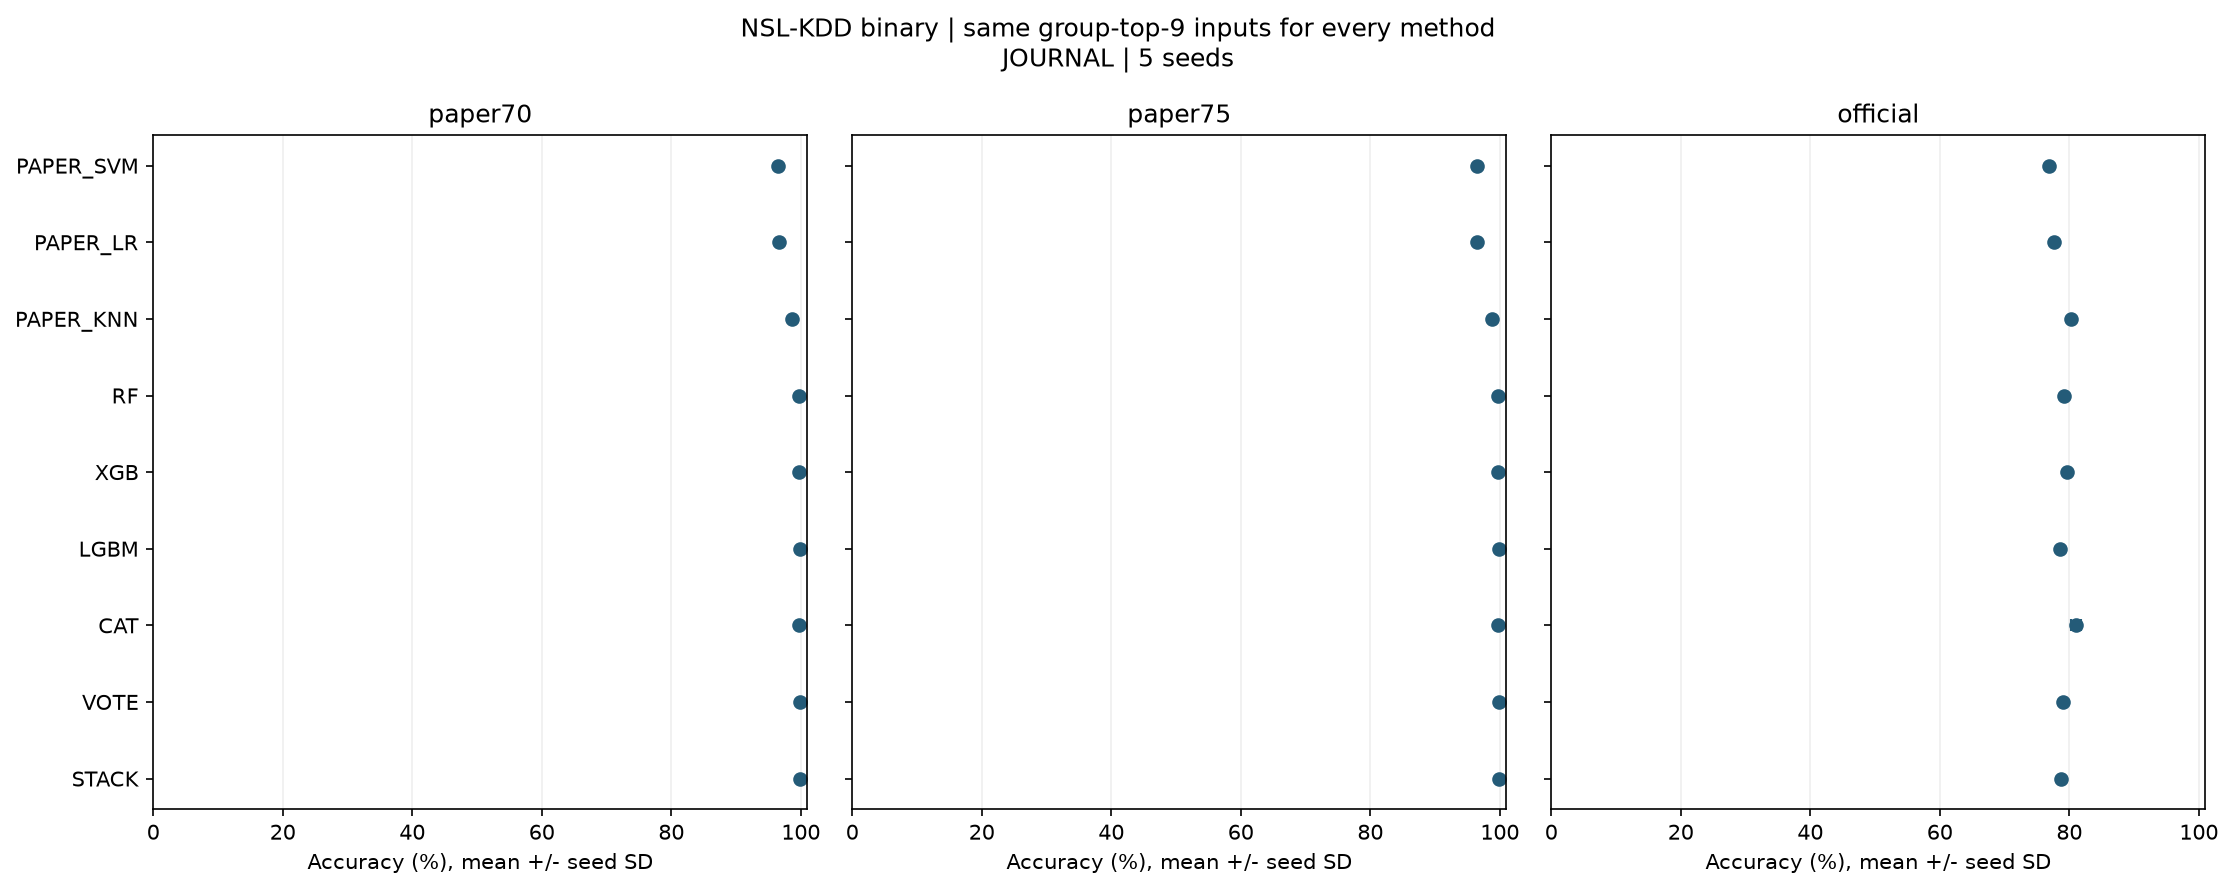

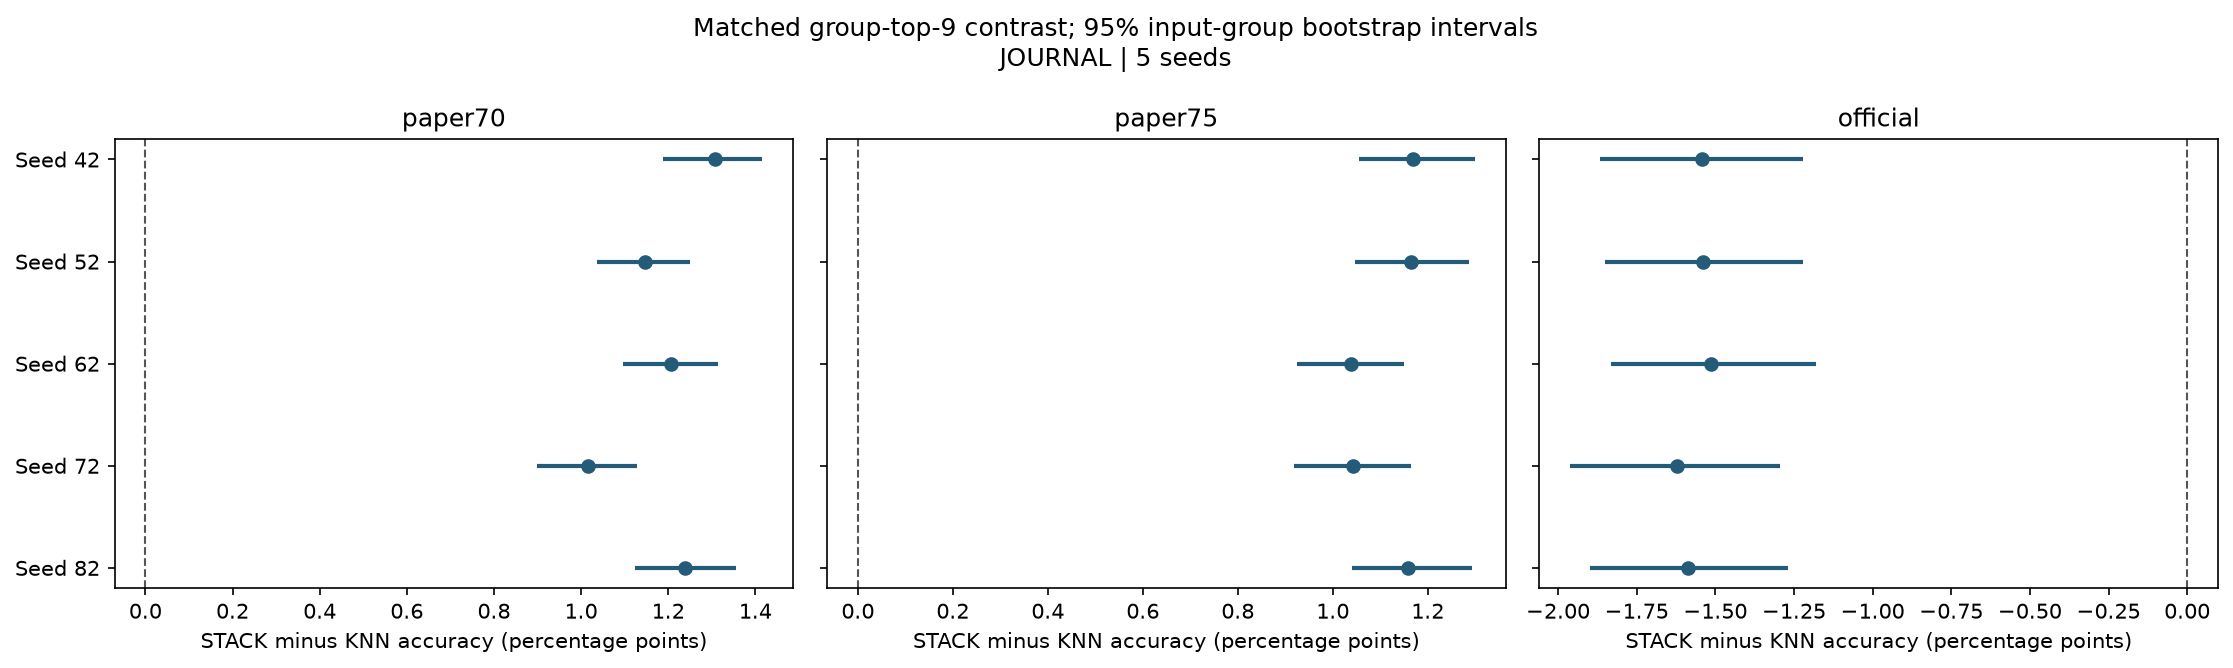

In [ ]:
from IPython.display import display, Image
for protocol in CFG.protocols:
    print(protocol, '|', status_label(CFG)['label'])
    table = summary[(summary.protocol==protocol) & (summary.subset=='all') &
        summary.metric.isin(['accuracy_percent','f1_attack','recall_attack','macro_f1','mcc'])]
    display(table.pivot(index='model_id', columns='metric', values='mean').round(4))
display(Image(filename=str(OUT_DIR / 'figures' / 'direct_accuracy.png')))
display(Image(filename=str(OUT_DIR / 'figures' / 'paired_accuracy_delta.png')))

In [ ]:
differences = pd.read_csv(OUT_DIR / 'paired_accuracy_summary.csv')
display(differences[differences.comparator.isin([
    'PAPER_KNN__rf_top9_group', 'PAPER_KNN__rf_threshold_encoded',
    'PAPER_SVM__rf_threshold_encoded', 'PAPER_LR__rf_threshold_encoded',
    'VOTE__rf_top9_group', 'STACK__all'])].round(4))
primary_cases = paired[paired.comparator=='PAPER_KNN__rf_top9_group']
display(primary_cases[['protocol','seed','delta_percentage_points',
    'target_only_correct','comparator_only_correct','mcnemar_exact_p',
    'group_bootstrap_delta95_low_pp','group_bootstrap_delta95_high_pp']].round(5))

,protocol,target,comparator,n_seeds,mean_delta_pp,std_delta_pp,positive_seeds
7,official,STACK__rf_top9_group,PAPER_KNN__rf_threshold_encoded,5,0.1242,0.0440,5
8,official,STACK__rf_top9_group,PAPER_KNN__rf_top9_group,5,-1.5614,0.0440,0
10,official,STACK__rf_top9_group,PAPER_LR__rf_threshold_encoded,5,3.2958,0.0440,5
13,official,STACK__rf_top9_group,PAPER_SVM__rf_threshold_encoded,5,2.4796,0.0440,5
18,official,STACK__rf_top9_group,STACK__all,5,-0.7887,0.4143,0
22,official,STACK__rf_top9_group,VOTE__rf_top9_group,5,-0.4081,0.0424,0
33,paper70,STACK__rf_top9_group,PAPER_KNN__rf_threshold_encoded,5,3.1377,1.5254,5
34,paper70,STACK__rf_top9_group,PAPER_KNN__rf_top9_group,5,1.1828,0.1099,5
36,paper70,STACK__rf_top9_group,PAPER_LR__rf_threshold_encoded,5,10.4350,0.6402,5
39,paper70,STACK__rf_top9_group,PAPER_SVM__rf_threshold_encoded,5,12.2063,0.1173,5


,protocol,seed,delta_percentage_points,target_only_correct,comparator_only_correct,mcnemar_exact_p,group_bootstrap_delta95_low_pp,group_bootstrap_delta95_high_pp
11,paper70,42,1.30715,505,11,0.0,1.18811,1.41574
37,paper70,52,1.14575,451,18,0.0,1.03726,1.24894
63,paper70,62,1.20660,472,16,0.0,1.09553,1.31509
89,paper70,72,1.01609,419,35,0.0,0.89971,1.12716
115,paper70,82,1.23836,487,19,0.0,1.12448,1.35495
141,paper75,42,1.16848,377,9,0.0,1.05417,1.29878
167,paper75,52,1.16530,380,13,0.0,1.04774,1.28596
193,paper75,62,1.03829,345,18,0.0,0.92404,1.14943
219,paper75,72,1.04147,361,33,0.0,0.91763,1.16535
245,paper75,82,1.15895,387,22,0.0,1.04137,1.29231


## 9. Cara menulis klaim riset

Gunakan bentuk: “Pada NSL-KDD biner, protokol [paper70/paper75/official] dan kasus evaluasi yang sama, STACK memperoleh accuracy X% dibandingkan rerun KNN Y%, dengan selisih berpasangan Z poin persentase.” Isi angka hanya dari output lengkap, sertakan variasi seed dan hasil kelas attack.

**Jangan mengklaim replikasi persis atau peningkatan signifikan terhadap angka asli 98,24%** tanpa indeks split dan pipeline penulis. Tabel angka historis disimpan terpisah dari perbandingan langsung. Keunggulan terhadap satu baseline juga tidak berarti terbaik terhadap seluruh model dalam grid. Laporkan bila KNN, voting, atau learner tunggal lebih baik.

Run jurnal penuh memakai lima seed dan tiga protokol. Jika dibatasi karena sumber daya, status menjadi `JOURNAL CUSTOM` dan keterbatasannya harus dilaporkan. `SMOKE` hanya validasi perangkat lunak.

Hasil utama: metrics per seed, mean/SD, paired accuracy, McNemar, bootstrap kontras utama, manifest split/OOF, selected features, warnings, prediksi, checkpoint terverifikasi, versi pustaka/hardware, checksum dataset, dan asumsi rekonstruksi paper.

In [ ]:
print('Lengkap:', (OUT_DIR / 'experiment_metadata.json').is_file())
print('Asumsi rekonstruksi:', OUT_DIR / 'paper_reconstruction.json')
print('Config lock:', OUT_DIR / 'direct_protocol_lock.json')
# Opsional arsip hasil (juga menyertakan prediksi dan checkpoint):
# import shutil
# archive = shutil.make_archive(str(OUT_DIR), 'zip', OUT_DIR)
# if IN_COLAB:
#     from google.colab import files
#     files.download(archive)

Lengkap: True
Asumsi rekonstruksi: /content/nslkdd_direct_results/paper_reconstruction.json
Config lock: /content/nslkdd_direct_results/direct_protocol_lock.json


## Sumber dan sitasi
- Vibhute et al. (2024), *Towards Detection of Network Anomalies using Machine Learning Algorithms on the NSL-KDD Benchmark Datasets*, Procedia Computer Science 233, 960–969. [DOI](https://doi.org/10.1016/j.procs.2024.03.285). Sections 3.1–3.4, 4; Figures 1–3; Tables 1–3.
- NSL-KDD, Canadian Institute for Cybersecurity, University of New Brunswick (2009). [Deskripsi resmi, format dan ketentuan redistribusi](https://www.unb.ca/cic/datasets/nsl.html).
- M. Tavallaee, E. Bagheri, W. Lu, A. A. Ghorbani (2009), *A Detailed Analysis of the KDD CUP 99 Data Set*, CISDA. [DOI](https://doi.org/10.1109/CISDA.2009.5356528).
- [Mirror NSL-KDD](https://github.com/Jehuty4949/NSL_KDD), commit `27bbbdf5c5cccf9970b8b6037a0f19dc09c5a0a9`. Mirror bukan distribusi resmi penulis paper 2024. Bytes dan ukuran input diverifikasi; data tidak dipilih berdasarkan hasil model.
- [scikit-learn: leakage](https://scikit-learn.org/stable/common_pitfalls.html), [SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html), [KNeighborsClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html).

In [ ]:
from google.colab import files
import shutil

folder = "/content/nsl_kdd"

shutil.make_archive(
    "/content/nsl_kdd",
    "zip",
    folder
)

files.download("/content/nsl_kdd")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import shutil

folder = "/content/nslkdd_direct_results"

shutil.make_archive(
    "/content/nslkdd_direct_results",
    "zip",
    folder
)

files.download("/content/nslkdd_direct_results")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>